(52933, 272)


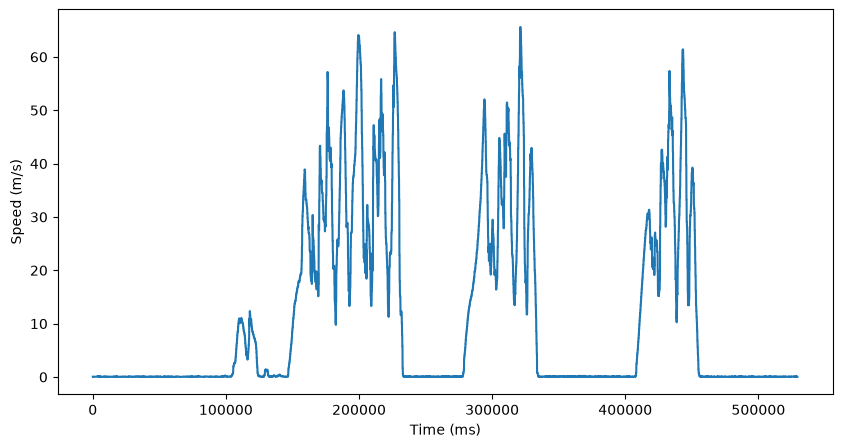

In [84]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = duckdb.sql("SELECT * FROM '4.parquet'").df()
print(df.shape)
df['VDM_GPS_SPEED'] = df['VDM_GPS_SPEED'].ffill()

plt.figure(figsize=(10,5))
plt.plot(df["Time_ms"], df["VDM_GPS_SPEED"])
plt.xlabel("Time (ms)")
plt.ylabel("Speed (m/s)")
plt.show()



In [92]:
wheel_radius = 0.2
df["v_ms"] = df["SME_TRQSPD_Speed"] * (12/41) * (2*np.pi/60) * 0.2
df["v_ms"] = df["v_ms"].ffill()

In [93]:
def find_slip(time, wheel):
    #wheel 1 = FL, wheel 2 = FR, wheel 3 = BL, wheel 4 = BR
    if wheel == 1:
        wheel_var = "TPERIPH_FL_DATA_WHEELSPEED" #front left wheel
    elif wheel == 2:
        wheel_var = "TPERIPH_FR_DATA_WHEELSPEED" #front right wheel
    elif wheel == 3:
        wheel_var = "TPERIPH_BL_DATA_WHEELSPEED" #back left wheel
    elif wheel == 4:
        wheel_var = "TPERIPH_BR_DATA_WHEELSPEED" #back right wheel

    idx = (df["Time_ms"] - time).abs().idxmin() #finds the nearest row from time
    
    vehicle_speed = df.loc[idx,"v_ms"]
    wheel_vel = (df.loc[idx,wheel_var] * 0.031) * (2*np.pi/60)*0.2

    if abs(vehicle_speed) < 0.01:   #protect against /0
        return float("nan")

    return float((wheel_vel - vehicle_speed)/abs(vehicle_speed))

find_slip(200000,2)

-0.9560050368309021

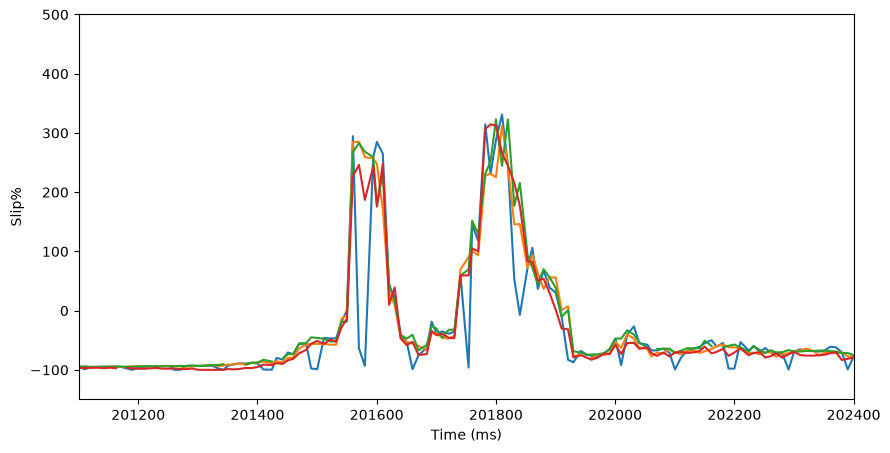

In [136]:

df["FLW_vel"] = (df["TPERIPH_FL_DATA_WHEELSPEED"] * 0.031) * (2*np.pi/60)*0.2
df["FRW_vel"] = (df["TPERIPH_FR_DATA_WHEELSPEED"] * 0.031) * (2*np.pi/60)*0.2
df["BLW_vel"] = (df["TPERIPH_BL_DATA_WHEELSPEED"] * 0.031) * (2*np.pi/60)*0.2
df["BRW_vel"] = (df["TPERIPH_BR_DATA_WHEELSPEED"] * 0.031) * (2*np.pi/60)*0.2

plt.figure(figsize=(10,5))
plt.xlim(201100, 202400)
plt.ylim(-150, 500)
plt.plot(df["Time_ms"], (df["FLW_vel"] - df["v_ms"])/abs(df["v_ms"])*100)
plt.plot(df["Time_ms"], (df["FRW_vel"] - df["v_ms"])/abs(df["v_ms"])*100)
plt.plot(df["Time_ms"], (df["BLW_vel"] - df["v_ms"])/abs(df["v_ms"])*100)
plt.plot(df["Time_ms"], (df["BRW_vel"] - df["v_ms"])/abs(df["v_ms"])*100)
plt.xlabel("Time (ms)")
plt.ylabel("Slip%")
plt.show()